# 선형회귀(regression)

## 문제: 보험 납입액 예측하기
미래를 대비하기 위해 보험에 가입하려고 하는데, 보험 상품마다 보장 범위와 조건이 달라서 보험 상품을 선택하거나 보험료를 예측하는데 어려움을 겪고 있다. 다양한 속성에 따른 보험료를 예측하는 인공지능 모델을 만들어 보자.

## 캐글을 활용한 데이터셋 확보 방법
* 캐글이란: 구글이 소유한 데이터사이언스 커뮤니티 플랫폼<br>
[상세한 내용은 다음 링크 참고바람](https://www.kaggle.com/code/jasonheesanglee/about-kaggle-kor)
* US Health Insurance Dataset: https://www.kaggle.com/datasets/teertha/ushealthinsurancedataset



### 1)파일 직접 다운받아 업로드

In [1]:
# 캐글에서 다운로드 받은 파일을 코랩에 업로드
from google.colab import files
myfile = files.upload()

Saving insurance.csv to insurance.csv


### 2)캐글 데이터를 바로 구글 드라이브로 저장
1. 구글 드라이브 마운트<br>
2. kagglehub의 다운로드 캐시 경로를 구글 드라이브로 직접 지정하도록 [KAGGLEHUB_CACHE] 환경 변수에 설정
3. 가져올 캐글 데이터셋 경로 지정
4. 다운로드
<img src="https://drive.google.com/uc?id=1GrwGBVVTJvZ9DIx1kYH1O2y4mBRG3AYc" height=350 width=600>


In [2]:
import os
import shutil
import kagglehub
from google.colab import drive

# 1. 구글 드라이브 마운트
drive.mount('/content/drive')

# 2. 저장할 구글 드라이브 대상 폴더 설정
drive_path = '/content/drive/MyDrive/Kaggle_Datasets'
os.makedirs(drive_path, exist_ok=True)

# 3. Kaggle 데이터셋 다운로드하여 임시 경로(down_path) 획득
down_path = kagglehub.dataset_download("teertha/ushealthinsurancedataset")

# 4. 다운로드 경로의 모든 요소를 검사하며 파일/폴더 맞춤형 복사 진행
for file_name in os.listdir(down_path):
    source_file = os.path.join(down_path, file_name)
    dest_file = os.path.join(drive_path, file_name)

    if os.path.isfile(source_file):
        # 파일인 경우: copy2 사용
        shutil.copy2(source_file, dest_file)
        print(f"파일 복사 완료: {file_name} -> {drive_path}")
    elif os.path.isdir(source_file):
        # 폴더인 경우: copytree에서 dirs_exist_ok=True 옵션 사용
        shutil.copytree(source_file, dest_file, dirs_exist_ok=True)
        print(f"폴더 복사 완료: {file_name} -> {drive_path}")

Mounted at /content/drive


100%|██████████| 16.0k/16.0k [00:00<00:00, 21.0MB/s]

Extracting files...
파일 복사 완료: insurance.csv -> /content/drive/MyDrive/Kaggle_Datasets


## 데이터 전처리
여기서는 1)번 방법으로 직접 업로드한 insurance.csv 파일 사용한다고 가정함

### 1)데이터셋 기본 정보 확인
1. 속성 구성 및 자료형
2. 데이터 갯수
3. 결측치 유무

In [3]:
import pandas as pd

In [4]:
# 가져온 csv 파일을 df에 저장
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
# 데이터셋 모양 확인
df.shape

(1338, 7)

In [6]:
# 데이터 속성의 자료형과 자료 개수 확인
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [7]:
# 데이터 갯수, 수치 데이터의 평균, 분산, 최솟값, 최댓값 등의 정보확인
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
#isna().sum()함수는 속성별 결측데이터의 갯수 정보를 제공합니다.
df.isna().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


### 2)데이터 전처리
1. 결측치 처리: 현재 데이터셋에는 결측치 없음
2. 필요없는 속성 삭제
3. 범주형 데이터를 수치형 데이터로 변환

In [9]:
# 지역은 크게 중요하지 않은 속성이라 판단하여 삭제
df = df.drop('region', axis=1)
df.head()

,age,sex,bmi,children,smoker,charges
0,19,female,27.900,0,yes,16884.92400
1,18,male,33.770,1,no,1725.55230
2,28,male,33.000,3,no,4449.46200
3,33,male,22.705,0,no,21984.47061
4,32,male,28.880,0,no,3866.85520


In [10]:
# 범주형인 성별과 흡연 항목을 수치형으로 변환
df['sex'] = df['sex'].replace({'male':0, 'female':1})
df['smoker'] = df['smoker'].replace({'no':0, 'yes':1})

/tmp/ipykernel_1333/3643254706.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['sex'] = df['sex'].replace({'male':0, 'female':1})
/tmp/ipykernel_1333/3643254706.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['smoker'] = df['smoker'].replace({'no':0, 'yes':1})


In [11]:
df.head()

,age,sex,bmi,children,smoker,charges
0,19,1,27.900,0,1,16884.92400
1,18,0,33.770,1,0,1725.55230
2,28,0,33.000,3,0,4449.46200
3,33,0,22.705,0,0,21984.47061
4,32,0,28.880,0,0,3866.85520


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   int64  
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   int64  
 5   charges   1338 non-null   float64
dtypes: float64(2), int64(4)
memory usage: 62.8 KB


### 3)속성 간 상관계수 확인

<Axes: >

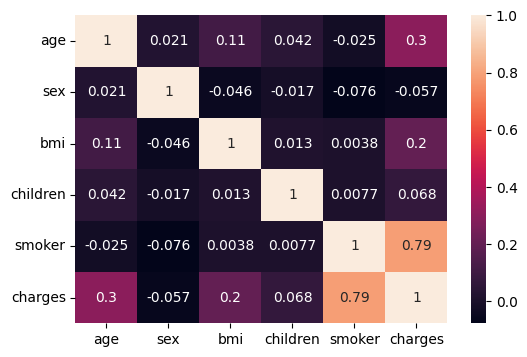

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.heatmap(df.corr(), annot=True)

## 인공지능 모델 훈련 및 성능 평가



### 1)인공지능 모델에 학습시킬 데이터 구성
1. 학습에 사용할 속성 선택
2. 스케일링


In [14]:
# 학습할 속성이 될 X(독립변수)와 타겟(목표)속성이 될 Y(종속변수)를 나누어 저장
X = df[['age', 'bmi', 'smoker']]
y = df['charges']

In [15]:
# Min-Max 정규화: 0~1 사이값으로 정규화

# Min-Max 정규화를 위해 데이터프레임을 배열로 변환
from sklearn.preprocessing import MinMaxScaler
data_array = X.values

# Min-Max 정규화 객체 생성
scaler = MinMaxScaler()

# 데이터 정규화
normalized_data = scaler.fit_transform(data_array)

# 정규화된 데이터를 다시 데이터프레임으로 변환
X = pd.DataFrame(normalized_data, columns=X.columns)

In [16]:
X

,age,bmi,smoker
0,0.021739,0.321227,1.0
1,0.000000,0.479150,0.0
2,0.217391,0.458434,0.0
3,0.326087,0.181464,0.0
4,0.304348,0.347592,0.0
...,...,...,...
1333,0.695652,0.403820,0.0
1334,0.000000,0.429379,0.0
1335,0.000000,0.562012,0.0
1336,0.065217,0.264730,0.0


### 2)훈련 데이터와 테스트 데이터 준비

In [17]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

### 3)모델 생성 및 학습
선형 회귀 모델 적용

In [18]:
# 선형회귀 모델로 학습 진행
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

LinearRegression()

### 4)성능 평가

In [19]:
# 선형 회귀(Leaner Regression)의 경우 결정계수를 기반으로 성능 평가
linear_model.score(X_test, y_test)

0.7189817541692232

### 5)학습시킨 모델을 통한 값 예측

In [20]:
# 학습시킨 모델로 X-test에 대한 y 값 예측
linear_predict = linear_model.predict(X_test)
linear_predict

array([ 6851.40622703,  6303.32884451, 15843.12911995, 12484.69141473,
        4131.17605052,  9197.82583893,  7904.00309712, 26164.4369559 ,
        7526.2579103 , 30185.47409083,  1226.01377583,  4212.97681933,
        7920.68534395,  9690.97810075, 12479.57122201, 11874.96999948,
        5631.01963855, 17801.84021022, 11819.11286683, 30879.76881867,
       34123.97327337,  4383.29726899,  1246.17051191,  6967.97538046,
        4016.22910848, 13977.58602425, 11782.94059127,  9418.70014619,
        5969.83175207, 31781.02815072,  -596.89169084, 34052.12409332,
       10330.83133292,  6927.66190829,  8319.72585322, 11371.34728575,
       14358.11550089, 13818.59756223, 10246.94821976,  8635.85049939,
       16844.73549155,  9599.68587613,  5964.28666451, 11581.78637921,
        6056.02727605,  7698.67245034,  6784.21710674, 33127.00346945,
       11820.04487879, 11316.22733669, 32138.35129687,  6157.54814007,
       10950.51608297, 13861.01687082, 12353.51061278, 14590.32179579,
      

### 6)예측한 값을 활용한 회귀 모델 성능 평가
R² Score (결정계수, Coefficient of Determination)를 활용한 회귀 모델 성능 평가
* 기본 개념: 평균으로 예측하는 기준 모델보다 예측 오차를 얼마나 줄였는가?
* R²는 모델의 제곱오차 합을 모든 실제값을 그 평균으로 예측했을 때의 제곱오차 합과 비교하는 회귀 성능 평가 지표. 최댓값은 1이며, 음수가 될 수도 있음.
$$R^2 = 1-\frac{\sum_{i=1}^{n}(y_i-\hat y_i)^2}
{\sum_{i=1}^{n}(y_i-\bar y)^2}$$

  $y_i$: 실제값 <br>
  $\hat y_i$: 모델의 예측값 <br>
  $\bar y$: 평가에 사용한 실제값들의 평균 <br>
  <br>

* R² = 1: 평가 데이터에서 모든 예측값이 실제값과 일치.good
* R² = 0: 평균으로 예측하는 기준 모델과 제곱오차 합이 같음. 평균 예측
* R² < 0: 평균으로 예측하는 기준 모델보다 제곱오차 합이 큼.
* 예를 들어, R² = 0.8이라면 해당 평가 데이터에서 평균 예측 기준 대비 제곱오차 합이 80% 감소했다는 뜻. '예측 정확도가 80%'라는 뜻은 아님.


In [21]:
from sklearn.metrics import r2_score

In [22]:
r2_score(y_test, linear_predict)

0.7189817541692232

## 새로운 데이터를 통한 모델 검증
모델이 잘 학습되었는지 테스트하기 위해, 임의의 새로운 검증 데이터를 만들고 보험료를 예측해 보자


In [23]:
import numpy as np

# 1. 가상의 테스트 데이터 생성
# 조건: 나이 35세, BMI 28.5, 흡연 여부 1 (Yes)
new_customer = pd.DataFrame([{
    'age': 35,
    'bmi': 28.5,
    'smoker': 1
}])

print("--- 입력한 가상 데이터 ---")
display(new_customer)

# 2. 새로운 데이터에 대해서도 모델 학습 시 사용했던 MinMaxScaler 정규화 진행
# scaler.transform()을 사용하여 기존 학습 데이터 기준과 동일하게 정규화
new_customer_array = new_customer.values
new_customer_normalized = scaler.transform(new_customer_array)

# 데이터프레임 형태로 변환
new_customer_df = pd.DataFrame(new_customer_normalized, columns=new_customer.columns)

print("\n--- MinMaxScaler한 데이터 ---")
display(new_customer_df)

# 3. 예측 수행
predicted_charge = linear_model.predict(new_customer_df)

# 4. 결과 출력
print("\n---예측 결과 ---")
print(f"이 고객의 예측 보험료: 약 ${predicted_charge[0]:,.2f}")

--- 입력한 가상 데이터 ---


,age,bmi,smoker
0,35,28.5,1



--- MinMaxScaler한 데이터 ---


,age,bmi,smoker
0,0.369565,0.337369,1.0



---예측 결과 ---
이 고객의 예측 보험료: 약 $30,763.20
